### **Descriptive Inequalities**

RQ1: How do healthcare travel-time accessibility and public-sector reliance vary across socioeconomic and geographic groups in South Africa?

The analysis include survey-weighted estimates by province, metro status, household income, food insecurity, medical aid coverage, vehicle ownership and household composition.

In [23]:
# ============================================================
# NOTEBOOK 02: DESCRIPTIVE HEALTHCARE ACCESS INEQUALITIES
# IMPORTS AND DATA LOADING
# ============================================================

from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Project directories
ROOT = Path.cwd().resolve().parent
PROCESSED_DIR = ROOT / "data" / "processed"
FIGURES_DIR = ROOT / "outputs" / "figures"
TABLES_DIR = ROOT / "outputs" / "tables"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

# Load analysis-ready datasets
household = pd.read_parquet(
    PROCESSED_DIR / "household_analysis.parquet"
)

person = pd.read_parquet(
    PROCESSED_DIR / "person_analysis.parquet"
)

# Validate
print("NOTEBOOK 02: DESCRIPTIVE INEQUALITIES")
print("-" * 55)

print("Household dataset:", household.shape)
print("Person dataset:   ", person.shape)

assert household["uqnr"].is_unique
assert household["house_wgt"].notna().all()
assert (household["house_wgt"] > 0).all()

print("\nDatasets loaded successfully.")

NOTEBOOK 02: DESCRIPTIVE INEQUALITIES
-------------------------------------------------------
Household dataset: (20095, 18)
Person dataset:    (67748, 8)

Datasets loaded successfully.


In [24]:
sns.set_theme(style="white")

plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 600,
    "font.size": 12,
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "axes.titlesize": 12,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

export_png = True
export_pdf = True

out_dir = str(FIGURES_DIR)
os.makedirs(out_dir, exist_ok=True)

colors = plt.cm.cividis(np.linspace(0.25, 0.85, 2))

In [25]:
import warnings

# Suppress warnings for cleaner output
warnings.filterwarnings('ignore')

In [26]:
# ============================================================
# NATIONAL SURVEY-WEIGHTED ACCESS ESTIMATES
# ============================================================

outcomes = {
    "travel30_hh": "Travel time ≥30 minutes",
    "public_sector_hh": "Usual public-sector facility"
}

results = []

for variable, label in outcomes.items():

    data = household.loc[
        household[variable].notna(),
        [variable, "house_wgt"]
    ]

    weighted_percent = (
        np.average(
            data[variable].astype(float),
            weights=data["house_wgt"]
        ) * 100
    )

    results.append({
        "Outcome": label,
        "Unweighted n": len(data),
        "Weighted (%)": round(weighted_percent, 2)
    })

national_access = pd.DataFrame(results)

print("NATIONAL HEALTHCARE ACCESS ESTIMATES")
print("-" * 60)

display(national_access)

assert len(national_access) == 2
assert national_access["Weighted (%)"].between(0, 100).all()

print("\nNational weighted estimates calculated successfully.")

NATIONAL HEALTHCARE ACCESS ESTIMATES
------------------------------------------------------------


,Outcome,Unweighted n,Weighted (%)
0,Travel time ≥30 minutes,20071,14.48
1,Usual public-sector facility,20084,73.29



National weighted estimates calculated successfully.


In [27]:
# ============================================================
# SURVEY-WEIGHTED HEALTHCARE ACCESS BY PROVINCE
# ============================================================

def weighted_percentage(data, outcome):
    valid = data.loc[
        data[outcome].notna(),
        [outcome, "house_wgt"]
    ]

    if valid.empty:
        return np.nan

    return (
        np.average(
            valid[outcome].astype(float),
            weights=valid["house_wgt"]
        ) * 100
    )


province_results = []

for province, group in household.groupby("province_hh"):

    province_results.append({
        "Province": province,

        "Households": len(group),

        "Travel n": group["travel30_hh"].notna().sum(),

        "Travel ≥30 min (%)": weighted_percentage(
            group, "travel30_hh"
        ),

        "Public sector n": group["public_sector_hh"].notna().sum(),

        "Public sector (%)": weighted_percentage(
            group, "public_sector_hh"
        )
    })


province_access = pd.DataFrame(province_results)

province_access = province_access.sort_values(
    "Travel ≥30 min (%)",
    ascending=False
).reset_index(drop=True)

# Round displayed percentages
province_access[
    ["Travel ≥30 min (%)", "Public sector (%)"]
] = province_access[
    ["Travel ≥30 min (%)", "Public sector (%)"]
].round(2)

print("GEOGRAPHIC INEQUALITIES IN HEALTHCARE ACCESS")
print("-" * 65)

display(province_access)

# Validation
assert len(province_access) == 9

assert province_access[
    ["Travel ≥30 min (%)", "Public sector (%)"]
].stack().between(0, 100).all()

assert province_access["Households"].sum() == len(household)

print("\nProvincial weighted estimates calculated successfully.")

GEOGRAPHIC INEQUALITIES IN HEALTHCARE ACCESS
-----------------------------------------------------------------


,Province,Households,Travel n,Travel ≥30 min (%),Public sector n,Public sector (%)
0,North West,1311,1308,27.97,1311,77.59
1,Mpumalanga,1568,1566,24.52,1567,79.66
2,Limpopo,2244,2243,21.78,2244,85.77
3,Northern Cape,858,858,21.63,858,73.61
4,Eastern Cape,2638,2636,20.92,2636,80.14
5,KwaZulu-Natal,3160,3154,17.08,3158,81.17
6,Free State,1193,1193,16.99,1193,74.81
7,Gauteng,5316,5309,5.64,5310,66.17
8,Western Cape,1807,1804,5.21,1807,56.78



Provincial weighted estimates calculated successfully.


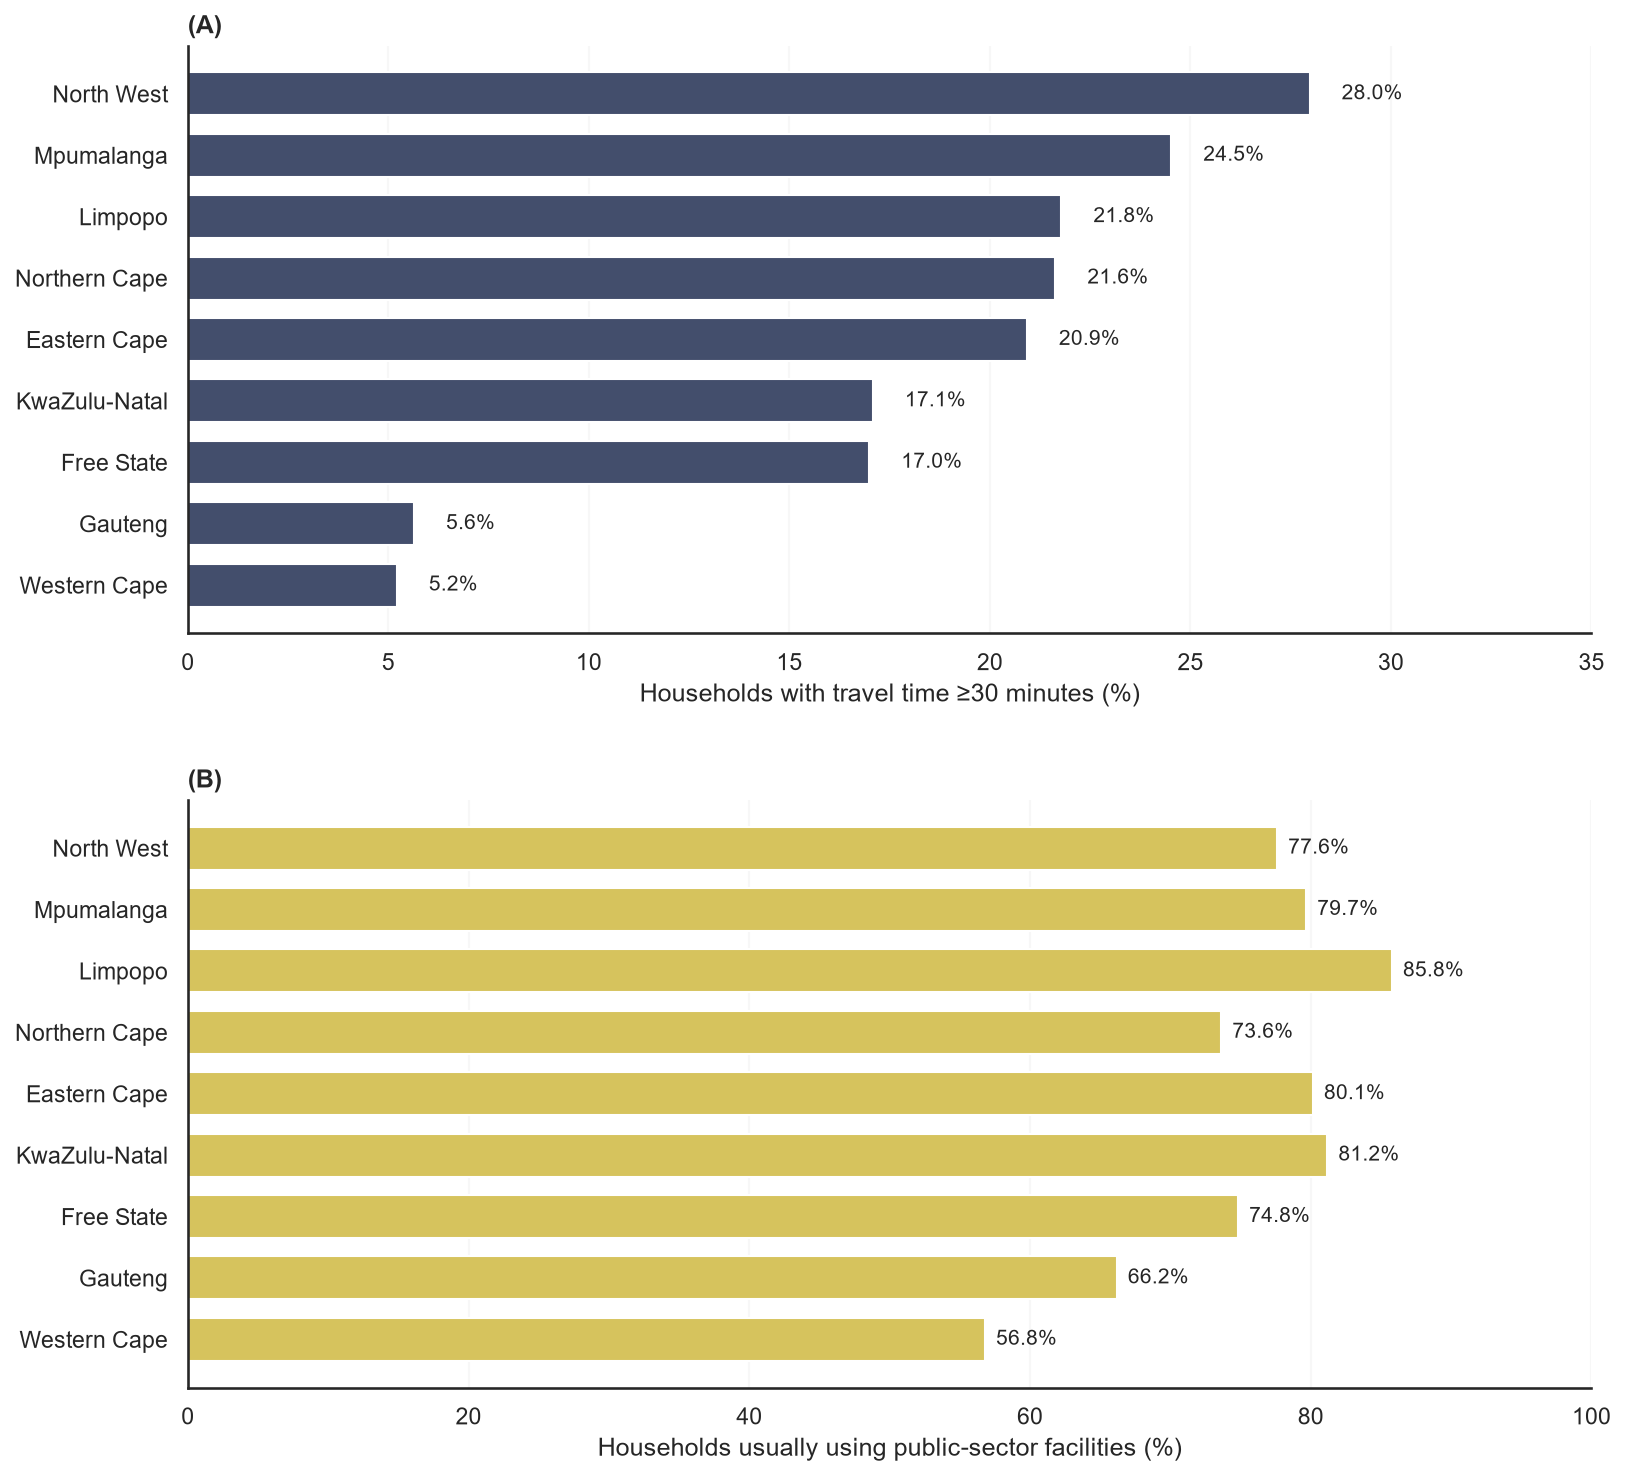

Figure exported to: C:\Users\tsholofelom\Documents\Research Projects\ghs-2025-healthcare-inequality\outputs\figures


In [28]:
# ============================================================
# PROVINCIAL HEALTHCARE ACCESS INEQUALITIES
# ============================================================


# Use the existing provincial ranking
plot_data = province_access.copy()
provinces = plot_data["Province"].tolist()
y = np.arange(len(provinces))


fig, axes = plt.subplots(
    2, 1,
    figsize=(11, 10),
    sharey=True
)

# Panel A: Travel time
axes[0].barh(
    y,
    plot_data["Travel ≥30 min (%)"],
    color=colors[0],
    height=0.7
)

axes[0].set_yticks(y, provinces)
axes[0].invert_yaxis()
axes[0].set_xlim(0, 35)
axes[0].set_xlabel("Households with travel time ≥30 minutes (%)")
axes[0].set_title(
    "(A)",
    loc="left",
    fontweight="bold"
)

# Panel B: Public-sector reliance
axes[1].barh(
    y,
    plot_data["Public sector (%)"],
    color=colors[1],
    height=0.7
)

axes[1].set_yticks(y, provinces)
axes[1].set_xlim(0, 100)
axes[1].set_xlabel("Households usually using public-sector facilities (%)")
axes[1].set_title(
    "(B)",
    loc="left",
    fontweight="bold"
)

# Value labels
for ax, column in zip(
    axes,
    ["Travel ≥30 min (%)", "Public sector (%)"]
):
    for i, value in enumerate(plot_data[column]):
        ax.text(
            value + 0.8,
            i,
            f"{value:.1f}%",
            va="center",
            fontsize=10
        )

    sns.despine(ax=ax)
    ax.grid(axis="x", alpha=0.15)
    ax.set_axisbelow(True)

fig.tight_layout(h_pad=2.5)

filename = "Provincial_Healthcare_Access_Inequalities"

if export_png:
    fig.savefig(
        os.path.join(out_dir, filename + ".png"),
        dpi=600,
        bbox_inches="tight"
    )

if export_pdf:
    fig.savefig(
        os.path.join(out_dir, filename + ".pdf"),
        bbox_inches="tight"
    )

plt.show()

print("Figure exported to:", out_dir)

In [29]:
# ============================================================
# METROPOLITAN VS NON-METROPOLITAN INEQUALITIES
# ============================================================

metro_results = []

for metro, group in household.groupby("metro_hh"):

    metro_results.append({
        "Area": metro,
        "Households": len(group),

        "Travel n": group["travel30_hh"].notna().sum(),

        "Travel ≥30 min (%)": weighted_percentage(
            group, "travel30_hh"
        ),

        "Public sector n": group["public_sector_hh"].notna().sum(),

        "Public sector (%)": weighted_percentage(
            group, "public_sector_hh"
        )
    })

metro_access = pd.DataFrame(metro_results)

metro_access[
    ["Travel ≥30 min (%)", "Public sector (%)"]
] = metro_access[
    ["Travel ≥30 min (%)", "Public sector (%)"]
].round(2)

print("METROPOLITAN VS NON-METROPOLITAN HEALTHCARE ACCESS")
print("-" * 65)

display(metro_access)

assert len(metro_access) == 2
assert metro_access["Households"].sum() == len(household)

print("\nMetropolitan comparison completed successfully.")

METROPOLITAN VS NON-METROPOLITAN HEALTHCARE ACCESS
-----------------------------------------------------------------


,Area,Households,Travel n,Travel ≥30 min (%),Public sector n,Public sector (%)
0,Metro,7971,7961,6.00,7965,64.25
1,Non-metro,12124,12110,21.62,12119,80.90



Metropolitan comparison completed successfully.


In [30]:
# ============================================================
# ABSOLUTE AND RELATIVE METRO INEQUALITIES
# ============================================================

outcomes = {
    "travel30_hh": "Travel time ≥30 minutes",
    "public_sector_hh": "Usual public-sector facility"
}

inequality_results = []

for outcome, label in outcomes.items():

    metro = weighted_percentage(
        household[household["metro_hh"] == "Metro"],
        outcome
    )

    nonmetro = weighted_percentage(
        household[household["metro_hh"] == "Non-metro"],
        outcome
    )

    inequality_results.append({
        "Outcome": label,
        "Metro (%)": metro,
        "Non-metro (%)": nonmetro,
        "Absolute gap (pp)": nonmetro - metro,
        "Prevalence ratio": nonmetro / metro
    })

metro_inequality = pd.DataFrame(inequality_results)

print("METROPOLITAN–NON-METROPOLITAN INEQUALITY MEASURES")
print("-" * 65)

display(metro_inequality.round(2))

assert len(metro_inequality) == 2
assert np.isfinite(
    metro_inequality[
        ["Absolute gap (pp)", "Prevalence ratio"]
    ].to_numpy()
).all()

print("\nGeographic inequality measures calculated successfully.")

METROPOLITAN–NON-METROPOLITAN INEQUALITY MEASURES
-----------------------------------------------------------------


,Outcome,Metro (%),Non-metro (%),Absolute gap (pp),Prevalence ratio
0,Travel time ≥30 minutes,6.00,21.62,15.63,3.61
1,Usual public-sector facility,64.25,80.90,16.65,1.26



Geographic inequality measures calculated successfully.


In [31]:
# ============================================================
# CONSTRUCT SURVEY-WEIGHTED INCOME QUINTILES
# ============================================================

# Retain households with valid per-capita income
income_data = household.loc[
    household["income_pc_hh"].notna(),
    ["income_pc_hh", "house_wgt"]
].copy()

# Sort by income
income_data = income_data.sort_values("income_pc_hh")

# Calculate cumulative survey weight
income_data["cumulative_weight"] = (
    income_data["house_wgt"].cumsum()
)

income_data["cumulative_share"] = (
    income_data["cumulative_weight"]
    / income_data["house_wgt"].sum()
)

# Assign identical incomes to the same quintile.
# Use the cumulative weight at each distinct income value.
income_shares = income_data.groupby(
    "income_pc_hh"
)["house_wgt"].sum().cumsum() / income_data["house_wgt"].sum()

income_quintiles = (
    np.searchsorted(
        [0.2, 0.4, 0.6, 0.8],
        income_shares.to_numpy(),
        side="left"
    ) + 1
)

income_mapping = pd.Series(
    income_quintiles,
    index=income_shares.index
)

household["income_quintile_hh"] = (
    household["income_pc_hh"]
    .map(income_mapping)
    .astype("Int64")
)

# Validate
print("HOUSEHOLD INCOME QUINTILES")
print("-" * 60)

print(
    household["income_quintile_hh"]
    .value_counts(dropna=False)
    .sort_index()
)

print("\nINCOME RANGES BY QUINTILE")
print("-" * 60)

display(
    household.groupby("income_quintile_hh")["income_pc_hh"]
    .agg(["min", "median", "max"])
    .round(2)
)

assert household["income_quintile_hh"].notna().sum() == (
    household["income_pc_hh"].notna().sum()
)

print("\nIncome quintiles constructed successfully.")

HOUSEHOLD INCOME QUINTILES
------------------------------------------------------------
income_quintile_hh
1       4192
2       4432
3       4205
4       3566
5       3268
<NA>     432
Name: count, dtype: Int64

INCOME RANGES BY QUINTILE
------------------------------------------------------------


,min,median,max
income_quintile_hh,,,
1,0.00,452.50,786.25
2,786.67,1139.89,1614.25
3,1615.00,2010.00,2999.00
4,3000.00,4400.00,6951.60
5,6958.00,12000.00,535000.00



Income quintiles constructed successfully.


In [32]:
# ============================================================
# HEALTHCARE ACCESS BY INCOME QUINTILE
# ============================================================

income_results = []

for quintile, group in household.groupby(
    "income_quintile_hh", dropna=True
):

    income_results.append({
        "Income quintile": f"Q{int(quintile)}",
        "Households": len(group),

        "Travel n": group["travel30_hh"].notna().sum(),

        "Travel ≥30 min (%)": weighted_percentage(
            group, "travel30_hh"
        ),

        "Public sector n": group["public_sector_hh"].notna().sum(),

        "Public sector (%)": weighted_percentage(
            group, "public_sector_hh"
        )
    })

income_access = pd.DataFrame(income_results)

income_access[
    ["Travel ≥30 min (%)", "Public sector (%)"]
] = income_access[
    ["Travel ≥30 min (%)", "Public sector (%)"]
].round(2)

print("HEALTHCARE ACCESS BY HOUSEHOLD INCOME QUINTILE")
print("-" * 65)

display(income_access)

# Validation
assert len(income_access) == 5
assert income_access["Households"].sum() == (
    household["income_quintile_hh"].notna().sum()
)

print("\nIncome-related healthcare access estimates calculated successfully.")

HEALTHCARE ACCESS BY HOUSEHOLD INCOME QUINTILE
-----------------------------------------------------------------


,Income quintile,Households,Travel n,Travel ≥30 min (%),Public sector n,Public sector (%)
0,Q1,4192,4188,22.96,4190,94.77
1,Q2,4432,4427,18.43,4431,93.32
2,Q3,4205,4200,13.74,4203,86.38
3,Q4,3566,3564,10.32,3565,69.83
4,Q5,3268,3264,7.66,3267,26.37



Income-related healthcare access estimates calculated successfully.


In [33]:
# ============================================================
# ABSOLUTE AND RELATIVE INCOME INEQUALITIES
# ============================================================

income_inequality_results = []

for outcome, label in {
    "travel30_hh": "Travel time ≥30 minutes",
    "public_sector_hh": "Usual public-sector facility"
}.items():

    q1 = weighted_percentage(
        household[household["income_quintile_hh"] == 1],
        outcome
    )

    q5 = weighted_percentage(
        household[household["income_quintile_hh"] == 5],
        outcome
    )

    income_inequality_results.append({
        "Outcome": label,
        "Q1 (%)": q1,
        "Q5 (%)": q5,
        "Absolute gap (pp)": q1 - q5,
        "Prevalence ratio": q1 / q5
    })

income_inequality = pd.DataFrame(income_inequality_results)

print("LOWEST–HIGHEST INCOME QUINTILE INEQUALITIES")
print("-" * 65)

display(income_inequality.round(2))

assert len(income_inequality) == 2
assert np.isfinite(
    income_inequality[
        ["Absolute gap (pp)", "Prevalence ratio"]
    ].to_numpy()
).all()

print("\nIncome inequality measures calculated successfully.")

LOWEST–HIGHEST INCOME QUINTILE INEQUALITIES
-----------------------------------------------------------------


,Outcome,Q1 (%),Q5 (%),Absolute gap (pp),Prevalence ratio
0,Travel time ≥30 minutes,22.96,7.66,15.31,3.00
1,Usual public-sector facility,94.77,26.37,68.40,3.59



Income inequality measures calculated successfully.


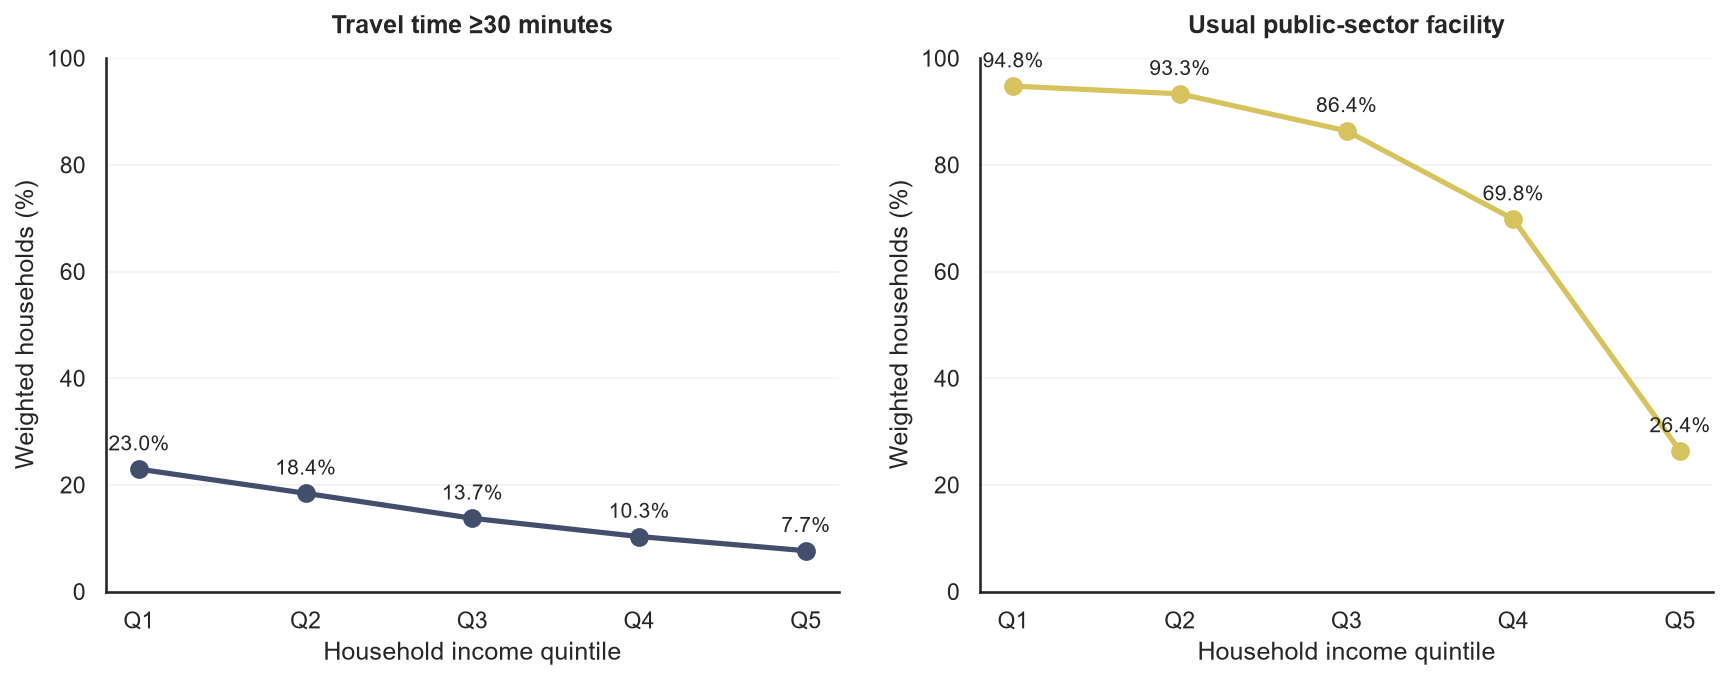

In [34]:
# ============================================================
# INCOME GRADIENT IN HEALTHCARE ACCESS
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5),
    sharex=True
)

outcome_specs = [
    ("Travel ≥30 min (%)", "Travel time ≥30 minutes"),
    ("Public sector (%)", "Usual public-sector facility")
]

x = np.arange(len(income_access))
labels = income_access["Income quintile"].tolist()

for ax, (column, title), color in zip(
    axes, outcome_specs, colors
):

    values = income_access[column].to_numpy()

    ax.plot(
        x, values,
        color=color,
        linewidth=2.5,
        marker="o",
        markersize=8
    )

    ax.set_xticks(x)
    ax.set_xticklabels(labels)

    ax.set_ylim(0, 100)
    ax.set_ylabel("Weighted households (%)")
    ax.set_xlabel("Household income quintile")

    ax.set_title(title, fontweight="bold", pad=12)

    ax.grid(axis="y", alpha=0.2)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    for xi, yi in zip(x, values):
        ax.annotate(
            f"{yi:.1f}%",
            (xi, yi),
            textcoords="offset points",
            xytext=(0, 9),
            ha="center",
            fontsize=10
        )

fig.tight_layout(pad=2)

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

fig.savefig(
    FIGURES_DIR / "income_healthcare_access_gradient.png",
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    FIGURES_DIR / "income_healthcare_access_gradient.pdf",
    bbox_inches="tight"
)

plt.show()

In [35]:
# ============================================================
# HEALTHCARE ACCESS BY FOOD INSECURITY
# ============================================================

food_results = []

food_labels = {
    0: "No food insecurity",
    1: "Any food insecurity"
}

for status, group in household.groupby("food_insecure_any_hh"):

    food_results.append({
        "Food insecurity": food_labels[int(status)],
        "Households": len(group),

        "Travel n": group["travel30_hh"].notna().sum(),

        "Travel ≥30 min (%)": weighted_percentage(
            group, "travel30_hh"
        ),

        "Public sector n": group["public_sector_hh"].notna().sum(),

        "Public sector (%)": weighted_percentage(
            group, "public_sector_hh"
        )
    })

food_access = pd.DataFrame(food_results)

food_access[
    ["Travel ≥30 min (%)", "Public sector (%)"]
] = food_access[
    ["Travel ≥30 min (%)", "Public sector (%)"]
].round(2)

print("HEALTHCARE ACCESS BY HOUSEHOLD FOOD INSECURITY")
print("-" * 65)

display(food_access)

# Validation
assert len(food_access) == 2
assert food_access["Households"].sum() == (
    household["food_insecure_any_hh"].notna().sum()
)

print("\nFood insecurity comparisons calculated successfully.")

HEALTHCARE ACCESS BY HOUSEHOLD FOOD INSECURITY
-----------------------------------------------------------------


,Food insecurity,Households,Travel n,Travel ≥30 min (%),Public sector n,Public sector (%)
0,No food insecurity,13972,13959,11.68,13966,66.47
1,Any food insecurity,6035,6026,21.66,6032,90.62



Food insecurity comparisons calculated successfully.


In [36]:
# ============================================================
# FOOD INSECURITY INEQUALITY MEASURES
# ============================================================

food_inequality_results = []

outcomes = {
    "travel30_hh": "Travel time ≥30 minutes",
    "public_sector_hh": "Usual public-sector facility"
}

for outcome, label in outcomes.items():

    food_secure = weighted_percentage(
        household[household["food_insecure_any_hh"] == 0],
        outcome
    )

    food_insecure = weighted_percentage(
        household[household["food_insecure_any_hh"] == 1],
        outcome
    )

    food_inequality_results.append({
        "Outcome": label,
        "No food insecurity (%)": food_secure,
        "Any food insecurity (%)": food_insecure,
        "Absolute gap (pp)": food_insecure - food_secure,
        "Prevalence ratio": food_insecure / food_secure
    })

food_inequality = pd.DataFrame(food_inequality_results)

print("FOOD INSECURITY: ABSOLUTE AND RELATIVE INEQUALITIES")
print("-" * 65)

display(food_inequality.round(2))

# Validation
assert len(food_inequality) == 2

assert np.isfinite(
    food_inequality[
        ["Absolute gap (pp)", "Prevalence ratio"]
    ].to_numpy()
).all()

print("\nFood insecurity inequality measures calculated successfully.")

FOOD INSECURITY: ABSOLUTE AND RELATIVE INEQUALITIES
-----------------------------------------------------------------


,Outcome,No food insecurity (%),Any food insecurity (%),Absolute gap (pp),Prevalence ratio
0,Travel time ≥30 minutes,11.68,21.66,9.99,1.86
1,Usual public-sector facility,66.47,90.62,24.14,1.36



Food insecurity inequality measures calculated successfully.


In [37]:
# ============================================================
# HEALTHCARE ACCESS BY MEDICAL AID COVERAGE
# ============================================================

medical_aid_results = []

medical_aid_labels = {
    0: "No household member covered",
    1: "At least one member covered"
}

for status, group in household.groupby("any_medical_aid_hh"):

    medical_aid_results.append({
        "Medical aid coverage": medical_aid_labels[int(status)],
        "Households": len(group),

        "Travel n": group["travel30_hh"].notna().sum(),

        "Travel ≥30 min (%)": weighted_percentage(
            group, "travel30_hh"
        ),

        "Public sector n": group["public_sector_hh"].notna().sum(),

        "Public sector (%)": weighted_percentage(
            group, "public_sector_hh"
        )
    })

medical_aid_access = pd.DataFrame(medical_aid_results)

medical_aid_access[
    ["Travel ≥30 min (%)", "Public sector (%)"]
] = medical_aid_access[
    ["Travel ≥30 min (%)", "Public sector (%)"]
].round(2)

print("HEALTHCARE ACCESS BY HOUSEHOLD MEDICAL AID COVERAGE")
print("-" * 70)

display(medical_aid_access)

# Validation
assert len(medical_aid_access) == 2

assert medical_aid_access["Households"].sum() == (
    household["any_medical_aid_hh"].notna().sum()
)

print("\nMedical aid comparisons calculated successfully.")

HEALTHCARE ACCESS BY HOUSEHOLD MEDICAL AID COVERAGE
----------------------------------------------------------------------


,Medical aid coverage,Households,Travel n,Travel ≥30 min (%),Public sector n,Public sector (%)
0,No household member covered,16080,16061,16.31,16072,88.71
1,At least one member covered,3931,3926,8.13,3928,19.05



Medical aid comparisons calculated successfully.


In [38]:
# ============================================================
# MEDICAL AID INEQUALITY MEASURES
# ============================================================

medical_aid_inequality_results = []

outcomes = {
    "travel30_hh": "Travel time ≥30 minutes",
    "public_sector_hh": "Usual public-sector facility"
}

for outcome, label in outcomes.items():

    no_cover = weighted_percentage(
        household[household["any_medical_aid_hh"] == 0],
        outcome
    )

    any_cover = weighted_percentage(
        household[household["any_medical_aid_hh"] == 1],
        outcome
    )

    medical_aid_inequality_results.append({
        "Outcome": label,
        "No member covered (%)": no_cover,
        "At least one covered (%)": any_cover,
        "Absolute gap (pp)": no_cover - any_cover,
        "Prevalence ratio": no_cover / any_cover
    })

medical_aid_inequality = pd.DataFrame(
    medical_aid_inequality_results
)

print("MEDICAL AID: ABSOLUTE AND RELATIVE INEQUALITIES")
print("-" * 70)

display(medical_aid_inequality.round(2))

# Validation
assert len(medical_aid_inequality) == 2

assert np.isfinite(
    medical_aid_inequality[
        ["Absolute gap (pp)", "Prevalence ratio"]
    ].to_numpy()
).all()

print("\nMedical aid inequality measures calculated successfully.")

MEDICAL AID: ABSOLUTE AND RELATIVE INEQUALITIES
----------------------------------------------------------------------


,Outcome,No member covered (%),At least one covered (%),Absolute gap (pp),Prevalence ratio
0,Travel time ≥30 minutes,16.31,8.13,8.17,2.00
1,Usual public-sector facility,88.71,19.05,69.66,4.66



Medical aid inequality measures calculated successfully.


In [39]:
# ============================================================
# HEALTHCARE ACCESS BY VEHICLE OWNERSHIP
# ============================================================

vehicle_results = []

vehicle_labels = {
    0: "No vehicle",
    1: "Owns a vehicle"
}

for status, group in household.groupby("vehicle_owner_hh"):

    vehicle_results.append({
        "Vehicle ownership": vehicle_labels[int(status)],
        "Households": len(group),

        "Travel n": group["travel30_hh"].notna().sum(),

        "Travel ≥30 min (%)": weighted_percentage(
            group, "travel30_hh"
        ),

        "Public sector n": group["public_sector_hh"].notna().sum(),

        "Public sector (%)": weighted_percentage(
            group, "public_sector_hh"
        )
    })

vehicle_access = pd.DataFrame(vehicle_results)

vehicle_access[
    ["Travel ≥30 min (%)", "Public sector (%)"]
] = vehicle_access[
    ["Travel ≥30 min (%)", "Public sector (%)"]
].round(2)

print("HEALTHCARE ACCESS BY HOUSEHOLD VEHICLE OWNERSHIP")
print("-" * 70)

display(vehicle_access)

# Validation
assert len(vehicle_access) == 2

assert vehicle_access["Households"].sum() == (
    household["vehicle_owner_hh"].notna().sum()
)

print("\nVehicle ownership comparisons calculated successfully.")

HEALTHCARE ACCESS BY HOUSEHOLD VEHICLE OWNERSHIP
----------------------------------------------------------------------


,Vehicle ownership,Households,Travel n,Travel ≥30 min (%),Public sector n,Public sector (%)
0,No vehicle,14476,14461,17.36,14468,89.60
1,Owns a vehicle,5615,5608,7.98,5614,36.57



Vehicle ownership comparisons calculated successfully.


In [40]:
# ============================================================
# VEHICLE OWNERSHIP INEQUALITY MEASURES
# ============================================================

vehicle_inequality_results = []

outcomes = {
    "travel30_hh": "Travel time ≥30 minutes",
    "public_sector_hh": "Usual public-sector facility"
}

for outcome, label in outcomes.items():

    no_vehicle = weighted_percentage(
        household[household["vehicle_owner_hh"] == 0],
        outcome
    )

    owns_vehicle = weighted_percentage(
        household[household["vehicle_owner_hh"] == 1],
        outcome
    )

    vehicle_inequality_results.append({
        "Outcome": label,
        "No vehicle (%)": no_vehicle,
        "Owns vehicle (%)": owns_vehicle,
        "Absolute gap (pp)": no_vehicle - owns_vehicle,
        "Prevalence ratio": no_vehicle / owns_vehicle
    })

vehicle_inequality = pd.DataFrame(vehicle_inequality_results)

print("VEHICLE OWNERSHIP: ABSOLUTE AND RELATIVE INEQUALITIES")
print("-" * 70)

display(vehicle_inequality.round(2))

# Validation
assert len(vehicle_inequality) == 2

assert np.isfinite(
    vehicle_inequality[
        ["Absolute gap (pp)", "Prevalence ratio"]
    ].to_numpy()
).all()

print("\nVehicle ownership inequality measures calculated successfully.")

VEHICLE OWNERSHIP: ABSOLUTE AND RELATIVE INEQUALITIES
----------------------------------------------------------------------


,Outcome,No vehicle (%),Owns vehicle (%),Absolute gap (pp),Prevalence ratio
0,Travel time ≥30 minutes,17.36,7.98,9.39,2.18
1,Usual public-sector facility,89.60,36.57,53.04,2.45



Vehicle ownership inequality measures calculated successfully.


In [ ]:
# ============================================================
# HEALTHCARE ACCESS BY TRANSPORT MODE
# ============================================================

# Inspect the exact transport labels
print("ORIGINAL TRANSPORT CATEGORIES")
print("-" * 60)

print(
    household["health_transport_hh"]
    .value_counts(dropna=False)
)

# Calculate weighted estimates
transport_results = []

for mode, group in household.groupby("health_transport_hh"):

    transport_results.append({
        "Transport mode": str(mode),
        "Households": len(group),

        "Travel n": group["travel30_hh"].notna().sum(),

        "Travel ≥30 min (%)": weighted_percentage(
            group, "travel30_hh"
        ),

        "Public sector n": group["public_sector_hh"].notna().sum(),

        "Public sector (%)": weighted_percentage(
            group, "public_sector_hh"
        )
    })

transport_access = pd.DataFrame(transport_results)

# Preserve the exact original category labels
# without converting them to a restrictive Categorical dtype
transport_access = (
    transport_access
    .sort_values("Transport mode")
    .reset_index(drop=True)
)

# Round displayed estimates
transport_access[
    ["Travel ≥30 min (%)", "Public sector (%)"]
] = transport_access[
    ["Travel ≥30 min (%)", "Public sector (%)"]
].round(2)

print("\nHEALTHCARE ACCESS BY TRANSPORT MODE")
print("-" * 70)

display(transport_access)

# Validation
assert len(transport_access) == 4

assert transport_access["Transport mode"].notna().all()

assert transport_access["Households"].sum() == (
    household["health_transport_hh"].notna().sum()
)

assert transport_access["Households"].sum() == 20093

print("\nTransport mode comparisons calculated successfully.")

ORIGINAL TRANSPORT CATEGORIES
------------------------------------------------------------
health_transport_hh
Walking                    9811
Public/shared transport    5708
Own transport              4292
Other                       282
NaN                           2
Name: count, dtype: int64

HEALTHCARE ACCESS BY TRANSPORT MODE
----------------------------------------------------------------------


,Transport mode,Households,Travel n,Travel ≥30 min (%),Public sector n,Public sector (%)
0,Other,282,276,20.67,277,69.60
1,Own transport,4292,4286,7.27,4291,24.23
2,Public/shared transport,5708,5705,16.37,5708,84.10
3,Walking,9811,9804,17.04,9808,93.28



Transport mode comparisons calculated successfully.


In [44]:
# ============================================================
# TRANSPORT-MODE INEQUALITY MEASURES
# ============================================================

transport_inequality_results = []

outcomes = {
    "travel30_hh": "Travel time ≥30 minutes",
    "public_sector_hh": "Usual public-sector facility"
}

reference = household[
    household["health_transport_hh"] == "Own transport"
]

comparison_groups = {
    "Walking": "Walking",
    "Public/shared transport": "Public/shared transport"
}

for outcome, label in outcomes.items():

    reference_pct = weighted_percentage(reference, outcome)

    for group_label, group_value in comparison_groups.items():

        comparison = household[
            household["health_transport_hh"] == group_value
        ]

        comparison_pct = weighted_percentage(
            comparison, outcome
        )

        transport_inequality_results.append({
            "Outcome": label,
            "Comparison": group_label,
            "Reference": "Own transport",
            "Comparison (%)": comparison_pct,
            "Reference (%)": reference_pct,
            "Absolute gap (pp)": comparison_pct - reference_pct,
            "Prevalence ratio": comparison_pct / reference_pct
        })

transport_inequality = pd.DataFrame(
    transport_inequality_results
)

print("TRANSPORT-MODE INEQUALITY MEASURES")
print("-" * 70)

display(transport_inequality.round(2))

# Validation
assert len(transport_inequality) == 4

assert np.isfinite(
    transport_inequality[
        ["Absolute gap (pp)", "Prevalence ratio"]
    ].to_numpy()
).all()

print("\nTransport-mode inequality measures calculated successfully.")

TRANSPORT-MODE INEQUALITY MEASURES
----------------------------------------------------------------------


,Outcome,Comparison,Reference,Comparison (%),Reference (%),Absolute gap (pp),Prevalence ratio
0,Travel time ≥30 minutes,Walking,Own transport,17.04,7.27,9.76,2.34
1,Travel time ≥30 minutes,Public/shared transport,Own transport,16.37,7.27,9.10,2.25
2,Usual public-sector facility,Walking,Own transport,93.28,24.23,69.04,3.85
3,Usual public-sector facility,Public/shared transport,Own transport,84.10,24.23,59.87,3.47



Transport-mode inequality measures calculated successfully.


In [45]:
# ============================================================
# DESIGN-ADJUSTED NATIONAL PREVALENCE
# ============================================================

from scipy.stats import t

def survey_proportion(data, outcome):
    """
    Survey-weighted proportion with a Taylor-linearised
    standard error for a stratified, clustered design.

    Assumes PSUs are sampled independently within strata
    and uses a with-replacement PSU variance approximation.
    """

    df = data[
        ["house_wgt", "psu", "stratum", outcome]
    ].dropna().copy()

    df = df[df["house_wgt"] > 0]

    y = df[outcome].astype(float)
    w = df["house_wgt"].astype(float)

    # Weighted prevalence
    p = np.sum(w * y) / np.sum(w)

    # Linearised contribution
    df["linearised"] = w * (y - p)

    # PSU-level totals within strata
    psu_totals = (
        df.groupby(["stratum", "psu"])["linearised"]
        .sum()
        .reset_index()
    )

    # Variance across PSUs within each stratum
    variance_total = 0.0
    n_psus = 0
    n_strata = 0

    for _, group in psu_totals.groupby("stratum"):

        m = len(group)

        if m < 2:
            raise ValueError(
                "Singleton PSU stratum detected; "
                "variance requires an explicit treatment."
            )

        values = group["linearised"].to_numpy()

        variance_total += (
            m / (m - 1)
        ) * np.sum((values - values.mean()) ** 2)

        n_psus += m
        n_strata += 1

    # Ratio estimator variance
    variance_p = variance_total / (w.sum() ** 2)

    se = np.sqrt(variance_p)

    # Design degrees of freedom
    df_design = n_psus - n_strata

    critical = t.ppf(0.975, df_design)

    ci_lower = max(0, p - critical * se)
    ci_upper = min(1, p + critical * se)

    return {
        "Outcome": outcome,
        "Valid households": len(df),
        "Weighted prevalence (%)": p * 100,
        "SE (pp)": se * 100,
        "95% CI lower (%)": ci_lower * 100,
        "95% CI upper (%)": ci_upper * 100,
        "Design df": df_design
    }


national_survey_results = pd.DataFrame([
    survey_proportion(household, "travel30_hh"),
    survey_proportion(household, "public_sector_hh")
])

print("DESIGN-ADJUSTED NATIONAL HEALTHCARE ACCESS ESTIMATES")
print("-" * 75)

display(national_survey_results.round(3))

DESIGN-ADJUSTED NATIONAL HEALTHCARE ACCESS ESTIMATES
---------------------------------------------------------------------------


,Outcome,Valid households,Weighted prevalence (%),SE (pp),95% CI lower (%),95% CI upper (%),Design df
0,travel30_hh,20071,14.482,0.384,13.730,15.235,2976
1,public_sector_hh,20084,73.289,0.417,72.472,74.105,2976


In [46]:
# ============================================================
# VERIFY SURVEY DESIGN STRUCTURE
# ============================================================

print("SURVEY DESIGN VALIDATION")
print("-" * 65)

print("Total households:", len(household))

print(
    "Unique PSU identifiers:",
    household["psu"].nunique()
)

print(
    "Unique strata:",
    household["stratum"].nunique()
)

print(
    "Unique stratum–PSU combinations:",
    household[["stratum", "psu"]]
    .drop_duplicates()
    .shape[0]
)

# Count PSUs within each stratum
psus_per_stratum = (
    household[["stratum", "psu"]]
    .drop_duplicates()
    .groupby("stratum")
    .size()
)

print("\nPSUs per stratum:")
display(psus_per_stratum.describe())

print(
    "\nSingleton strata:",
    (psus_per_stratum == 1).sum()
)

# Check whether PSU identifiers appear in multiple strata
psu_strata = household.groupby("psu")["stratum"].nunique()

print(
    "\nPSU identifiers appearing in multiple strata:",
    (psu_strata > 1).sum()
)

# Verify design structure for each outcome
for outcome in ["travel30_hh", "public_sector_hh"]:

    valid = household.loc[
        household[outcome].notna()
        & household["house_wgt"].notna()
        & (household["house_wgt"] > 0)
    ]

    n_strata = valid["stratum"].nunique()

    n_psus = (
        valid[["stratum", "psu"]]
        .drop_duplicates()
        .shape[0]
    )

    print(f"\nOutcome: {outcome}")
    print("Strata:", n_strata)
    print("Stratum–PSU combinations:", n_psus)
    print("Design df:", n_psus - n_strata)

print("\nSurvey design validation completed.")

SURVEY DESIGN VALIDATION
-----------------------------------------------------------------
Total households: 20095
Unique PSU identifiers: 3226
Unique strata: 248
Unique stratum–PSU combinations: 3226

PSUs per stratum:


count    248.000000
mean      13.008065
std        6.715739
min        2.000000
25%        8.000000
50%       12.000000
75%       16.000000
max       48.000000
dtype: float64


Singleton strata: 0

PSU identifiers appearing in multiple strata: 0

Outcome: travel30_hh
Strata: 248
Stratum–PSU combinations: 3224
Design df: 2976

Outcome: public_sector_hh
Strata: 248
Stratum–PSU combinations: 3224
Design df: 2976

Survey design validation completed.


In [47]:
# ============================================================
# SURVEY-DESIGN-AWARE DOMAIN ESTIMATOR
# ============================================================

from scipy.stats import t

def survey_domain_proportion(
    data,
    outcome,
    domain_variable,
    domain_value
):
    """
    Survey-weighted domain prevalence with Taylor-linearised
    standard errors.

    Retains all sampled PSUs and strata when calculating
    domain variance.

    Uses a with-replacement PSU variance approximation.
    """

    df = data[
        [
            "house_wgt",
            "psu",
            "stratum",
            outcome,
            domain_variable
        ]
    ].copy()

    # Retain the full survey design
    df = df.dropna(
        subset=["house_wgt", "psu", "stratum"]
    )

    df = df[df["house_wgt"] > 0].copy()

    # Domain membership and outcome validity
    in_domain = df[domain_variable].eq(domain_value).fillna(False)
    valid_outcome = df[outcome].notna()

    eligible = in_domain & valid_outcome

    if not eligible.any():
        raise ValueError("No valid observations in the selected domain.")

    # Weighted domain prevalence
    domain_weight = df.loc[eligible, "house_wgt"].sum()

    p = (
        df.loc[eligible, "house_wgt"]
        * df.loc[eligible, outcome].astype(float)
    ).sum() / domain_weight

    # Zero contributions outside the domain
    df["linearised"] = 0.0

    df.loc[eligible, "linearised"] = (
        df.loc[eligible, "house_wgt"]
        * (df.loc[eligible, outcome].astype(float) - p)
    )

    # PSU totals across the full design
    psu_totals = (
        df.groupby(["stratum", "psu"])["linearised"]
        .sum()
        .reset_index()
    )

    variance_total = 0.0

    for _, group in psu_totals.groupby("stratum"):

        m = len(group)

        if m < 2:
            raise ValueError(
                "Singleton stratum in full survey design."
            )

        values = group["linearised"].to_numpy()

        variance_total += (
            m / (m - 1)
        ) * np.sum(
            (values - values.mean()) ** 2
        )

    se = np.sqrt(
        variance_total / domain_weight**2
    )

    # Full-design degrees of freedom
    n_psus = len(psu_totals)
    n_strata = psu_totals["stratum"].nunique()

    design_df = n_psus - n_strata

    critical = t.ppf(0.975, design_df)

    return {
        "Domain": str(domain_value),
        "Valid households": int(eligible.sum()),
        "Prevalence (%)": p * 100,
        "SE (pp)": se * 100,
        "95% CI lower (%)": max(0, p - critical * se) * 100,
        "95% CI upper (%)": min(1, p + critical * se) * 100,
        "Design df": design_df
    }


# Validate the estimator using metropolitan status
metro_ci_results = []

for outcome in ["travel30_hh", "public_sector_hh"]:

    for area in ["Metro", "Non-metro"]:

        result = survey_domain_proportion(
            household,
            outcome,
            "metro_hh",
            area
        )

        result["Outcome"] = outcome

        metro_ci_results.append(result)

metro_ci = pd.DataFrame(metro_ci_results)

print("DESIGN-ADJUSTED METROPOLITAN ACCESS ESTIMATES")
print("-" * 75)

display(
    metro_ci[
        [
            "Outcome",
            "Domain",
            "Valid households",
            "Prevalence (%)",
            "SE (pp)",
            "95% CI lower (%)",
            "95% CI upper (%)",
            "Design df"
        ]
    ].round(3)
)

assert len(metro_ci) == 4

assert (metro_ci["Design df"] == 2978).all()

print("\nDomain estimation completed successfully.")

DESIGN-ADJUSTED METROPOLITAN ACCESS ESTIMATES
---------------------------------------------------------------------------


,Outcome,Domain,Valid households,Prevalence (%),SE (pp),95% CI lower (%),95% CI upper (%),Design df
0,travel30_hh,Metro,7961,5.996,0.360,5.289,6.702,2978
1,travel30_hh,Non-metro,12110,21.624,0.623,20.403,22.844,2978
2,public_sector_hh,Metro,7965,64.245,0.683,62.905,65.585,2978
3,public_sector_hh,Non-metro,12119,80.897,0.495,79.926,81.868,2978



Domain estimation completed successfully.


In [48]:
# ============================================================
# DESIGN-ADJUSTED GEOGRAPHIC INEQUALITY MEASURES
# ============================================================

def survey_domain_contrast(
    data, outcome, domain_variable,
    group_a, group_b
):
    """
    Survey-design-adjusted comparison of two domain prevalences.

    Calculates:
    - Absolute prevalence difference (percentage points)
    - Prevalence ratio
    - Taylor-linearised 95% confidence intervals

    Retains the full PSU-stratum survey structure.
    Uses a with-replacement PSU variance approximation.
    """

    df = data[
        ["house_wgt", "psu", "stratum",
         outcome, domain_variable]
    ].copy()

    df = df.dropna(
        subset=["house_wgt", "psu", "stratum"]
    )

    df = df[df["house_wgt"] > 0].copy()

    y = df[outcome].astype(float)

    valid = df[outcome].notna()

    mask_a = (
        df[domain_variable].eq(group_a).fillna(False)
        & valid
    )

    mask_b = (
        df[domain_variable].eq(group_b).fillna(False)
        & valid
    )

    w = df["house_wgt"].astype(float)

    Wa = w[mask_a].sum()
    Wb = w[mask_b].sum()

    if Wa <= 0 or Wb <= 0:
        raise ValueError("One comparison group is empty.")

    pa = (w[mask_a] * y[mask_a]).sum() / Wa
    pb = (w[mask_b] * y[mask_b]).sum() / Wb

    if pb <= 0:
        raise ValueError(
            "Reference prevalence must be positive."
        )

    # Linearised contributions for each domain prevalence
    df["lin_a"] = 0.0
    df["lin_b"] = 0.0

    df.loc[mask_a, "lin_a"] = (
        w[mask_a] * (y[mask_a] - pa) / Wa
    )

    df.loc[mask_b, "lin_b"] = (
        w[mask_b] * (y[mask_b] - pb) / Wb
    )

    # Absolute difference: pa - pb
    df["lin_diff"] = df["lin_a"] - df["lin_b"]

    # Log prevalence ratio: log(pa / pb)
    if pa <= 0:
        raise ValueError(
            "Comparison prevalence must be positive."
        )

    df["lin_logpr"] = (
        df["lin_a"] / pa - df["lin_b"] / pb
    )

    # Aggregate linearised contributions at PSU level
    psu = (
        df.groupby(["stratum", "psu"])[
            ["lin_diff", "lin_logpr"]
        ]
        .sum()
        .reset_index()
    )

    def design_variance(column):
        total = 0.0

        for _, group in psu.groupby("stratum"):

            m = len(group)

            if m < 2:
                raise ValueError(
                    "Singleton stratum detected."
                )

            values = group[column].to_numpy()

            total += (
                m / (m - 1)
                * np.sum((values - values.mean()) ** 2)
            )

        return total

    se_diff = np.sqrt(design_variance("lin_diff"))
    se_logpr = np.sqrt(design_variance("lin_logpr"))

    design_df = (
        len(psu) - psu["stratum"].nunique()
    )

    critical = t.ppf(0.975, design_df)

    difference = (pa - pb) * 100
    ratio = pa / pb

    diff_lower = difference - critical * se_diff * 100
    diff_upper = difference + critical * se_diff * 100

    # Log-scale confidence interval for prevalence ratio
    pr_lower = np.exp(
        np.log(ratio) - critical * se_logpr
    )

    pr_upper = np.exp(
        np.log(ratio) + critical * se_logpr
    )

    return {
        "Outcome": outcome,
        "Comparison": str(group_a),
        "Reference": str(group_b),
        "Difference (pp)": difference,
        "Difference CI lower": diff_lower,
        "Difference CI upper": diff_upper,
        "Prevalence ratio": ratio,
        "PR CI lower": pr_lower,
        "PR CI upper": pr_upper,
        "Design df": design_df
    }


# Compare non-metropolitan against metropolitan households
metro_contrasts = pd.DataFrame([
    survey_domain_contrast(
        household,
        outcome,
        "metro_hh",
        "Non-metro",
        "Metro"
    )
    for outcome in ["travel30_hh", "public_sector_hh"]
])

print("DESIGN-ADJUSTED METROPOLITAN INEQUALITIES")
print("-" * 75)

display(metro_contrasts.round(3))

# Validation
assert len(metro_contrasts) == 2
assert (metro_contrasts["Design df"] == 2978).all()

assert (
    metro_contrasts["Difference CI lower"]
    < metro_contrasts["Difference (pp)"]
).all()

assert (
    metro_contrasts["Difference (pp)"]
    < metro_contrasts["Difference CI upper"]
).all()

print("\nGeographic inequality inference completed successfully.")

DESIGN-ADJUSTED METROPOLITAN INEQUALITIES
---------------------------------------------------------------------------


,Outcome,Comparison,Reference,Difference (pp),Difference CI lower,Difference CI upper,Prevalence ratio,PR CI lower,PR CI upper,Design df
0,travel30_hh,Non-metro,Metro,15.628,14.218,17.038,3.607,3.165,4.11,2978
1,public_sector_hh,Non-metro,Metro,16.652,14.997,18.306,1.259,1.229,1.29,2978



Geographic inequality inference completed successfully.


In [49]:
# ============================================================
# DESIGN-ADJUSTED INCOME INEQUALITIES
# ============================================================

income_contrasts = pd.DataFrame([
    survey_domain_contrast(
        household,
        outcome,
        "income_quintile_hh",
        1,
        5
    )
    for outcome in ["travel30_hh", "public_sector_hh"]
])

# Use descriptive labels
income_contrasts["Comparison"] = "Q1 (Lowest income)"
income_contrasts["Reference"] = "Q5 (Highest income)"

print("DESIGN-ADJUSTED INCOME INEQUALITIES: Q1 VS Q5")
print("-" * 75)

display(income_contrasts.round(3))

# Validation
assert len(income_contrasts) == 2

assert (income_contrasts["Design df"] == 2978).all()

assert (
    income_contrasts["Difference CI lower"]
    < income_contrasts["Difference (pp)"]
).all()

assert (
    income_contrasts["Difference (pp)"]
    < income_contrasts["Difference CI upper"]
).all()

assert (
    income_contrasts["PR CI lower"]
    < income_contrasts["Prevalence ratio"]
).all()

assert (
    income_contrasts["Prevalence ratio"]
    < income_contrasts["PR CI upper"]
).all()

print("\nIncome inequality inference completed successfully.")

DESIGN-ADJUSTED INCOME INEQUALITIES: Q1 VS Q5
---------------------------------------------------------------------------


,Outcome,Comparison,Reference,Difference (pp),Difference CI lower,Difference CI upper,Prevalence ratio,PR CI lower,PR CI upper,Design df
0,travel30_hh,Q1 (Lowest income),Q5 (Highest income),15.306,13.387,17.224,2.999,2.574,3.494,2978
1,public_sector_hh,Q1 (Lowest income),Q5 (Highest income),68.404,66.422,70.387,3.594,3.357,3.848,2978



Income inequality inference completed successfully.


In [50]:
# ============================================================
# SOCIOECONOMIC VULNERABILITY CONTRASTS
# ============================================================

comparisons = [
    {
        "Indicator": "Food insecurity",
        "Variable": "food_insecure_any_hh",
        "Comparison": 1,
        "Reference": 0,
        "Comparison label": "Any food insecurity",
        "Reference label": "No food insecurity"
    },
    {
        "Indicator": "Medical aid coverage",
        "Variable": "any_medical_aid_hh",
        "Comparison": 0,
        "Reference": 1,
        "Comparison label": "No member covered",
        "Reference label": "At least one covered"
    },
    {
        "Indicator": "Vehicle ownership",
        "Variable": "vehicle_owner_hh",
        "Comparison": 0,
        "Reference": 1,
        "Comparison label": "No vehicle",
        "Reference label": "Owns vehicle"
    }
]

vulnerability_results = []

for comparison in comparisons:

    for outcome in ["travel30_hh", "public_sector_hh"]:

        result = survey_domain_contrast(
            household,
            outcome,
            comparison["Variable"],
            comparison["Comparison"],
            comparison["Reference"]
        )

        result["Indicator"] = comparison["Indicator"]
        result["Comparison"] = comparison["Comparison label"]
        result["Reference"] = comparison["Reference label"]

        vulnerability_results.append(result)

vulnerability_contrasts = pd.DataFrame(
    vulnerability_results
)

# Arrange columns for interpretation
columns = [
    "Indicator",
    "Outcome",
    "Comparison",
    "Reference",
    "Difference (pp)",
    "Difference CI lower",
    "Difference CI upper",
    "Prevalence ratio",
    "PR CI lower",
    "PR CI upper",
    "Design df"
]

vulnerability_contrasts = vulnerability_contrasts[columns]

print("DESIGN-ADJUSTED SOCIOECONOMIC VULNERABILITY INEQUALITIES")
print("-" * 75)

display(vulnerability_contrasts.round(3))

# Validation
assert len(vulnerability_contrasts) == 6

assert (
    vulnerability_contrasts["Design df"] == 2978
).all()

assert (
    vulnerability_contrasts["PR CI lower"]
    < vulnerability_contrasts["Prevalence ratio"]
).all()

assert (
    vulnerability_contrasts["Prevalence ratio"]
    < vulnerability_contrasts["PR CI upper"]
).all()

print("\nSocioeconomic vulnerability inference completed successfully.")

DESIGN-ADJUSTED SOCIOECONOMIC VULNERABILITY INEQUALITIES
---------------------------------------------------------------------------


,Indicator,Outcome,Comparison,Reference,Difference (pp),Difference CI lower,Difference CI upper,Prevalence ratio,PR CI lower,PR CI upper,Design df
0,Food insecurity,travel30_hh,Any food insecurity,No food insecurity,9.986,8.390,11.582,1.855,1.697,2.028,2978
1,Food insecurity,public_sector_hh,Any food insecurity,No food insecurity,24.143,22.678,25.609,1.363,1.337,1.390,2978
2,Medical aid coverage,travel30_hh,No member covered,At least one covered,8.173,6.925,9.420,2.005,1.767,2.275,2978
3,Medical aid coverage,public_sector_hh,No member covered,At least one covered,69.659,68.227,71.092,4.657,4.354,4.980,2978
4,Vehicle ownership,travel30_hh,No vehicle,Owns vehicle,9.386,8.222,10.549,2.177,1.945,2.436,2978
5,Vehicle ownership,public_sector_hh,No vehicle,Owns vehicle,53.036,51.446,54.627,2.450,2.354,2.551,2978



Socioeconomic vulnerability inference completed successfully.


In [51]:
# ============================================================
# CONSOLIDATED INEQUALITY RESULTS TABLE
# ============================================================

# Combine all validated survey-adjusted contrasts
all_contrasts = pd.concat(
    [
        metro_contrasts.assign(
            Indicator="Geographic location"
        ),
        income_contrasts.assign(
            Indicator="Household income"
        ),
        vulnerability_contrasts
    ],
    ignore_index=True
)

# Descriptive outcome labels
outcome_labels = {
    "travel30_hh": "Travel time ≥30 minutes",
    "public_sector_hh": "Usual public-sector facility"
}

def format_ci(estimate, lower, upper):
    return f"{estimate:.2f} ({lower:.2f}–{upper:.2f})"

# Build manuscript-ready table
inequality_table = pd.DataFrame({
    "Indicator": all_contrasts["Indicator"],
    "Outcome": all_contrasts["Outcome"].map(outcome_labels),
    "Comparison": all_contrasts["Comparison"],
    "Reference": all_contrasts["Reference"],
    "Difference, pp (95% CI)": [
        format_ci(est, lo, hi)
        for est, lo, hi in zip(
            all_contrasts["Difference (pp)"],
            all_contrasts["Difference CI lower"],
            all_contrasts["Difference CI upper"]
        )
    ],
    "Prevalence ratio (95% CI)": [
        format_ci(est, lo, hi)
        for est, lo, hi in zip(
            all_contrasts["Prevalence ratio"],
            all_contrasts["PR CI lower"],
            all_contrasts["PR CI upper"]
        )
    ]
})

# Sort into thematic groups
indicator_order = [
    "Geographic location",
    "Household income",
    "Food insecurity",
    "Medical aid coverage",
    "Vehicle ownership"
]

inequality_table["Indicator"] = pd.Categorical(
    inequality_table["Indicator"],
    categories=indicator_order,
    ordered=True
)

inequality_table = (
    inequality_table
    .sort_values(["Indicator", "Outcome"])
    .reset_index(drop=True)
)

# Save both formatted and numerical results
inequality_table.to_csv(
    TABLES_DIR / "table_inequality_contrasts.csv",
    index=False
)

all_contrasts.to_csv(
    TABLES_DIR / "inequality_contrasts_numeric.csv",
    index=False
)

print("TABLE: SURVEY-DESIGN-ADJUSTED HEALTHCARE ACCESS INEQUALITIES")
print("-" * 80)

display(inequality_table)

print("\nSaved:")
print(TABLES_DIR / "table_inequality_contrasts.csv")
print(TABLES_DIR / "inequality_contrasts_numeric.csv")

assert len(inequality_table) == 10
assert inequality_table["Outcome"].notna().all()

print("\nConsolidated inequality table completed successfully.")

TABLE: SURVEY-DESIGN-ADJUSTED HEALTHCARE ACCESS INEQUALITIES
--------------------------------------------------------------------------------


,Indicator,Outcome,Comparison,Reference,"Difference, pp (95% CI)",Prevalence ratio (95% CI)
0,Geographic location,Travel time ≥30 minutes,Non-metro,Metro,15.63 (14.22–17.04),3.61 (3.16–4.11)
1,Geographic location,Usual public-sector facility,Non-metro,Metro,16.65 (15.00–18.31),1.26 (1.23–1.29)
2,Household income,Travel time ≥30 minutes,Q1 (Lowest income),Q5 (Highest income),15.31 (13.39–17.22),3.00 (2.57–3.49)
3,Household income,Usual public-sector facility,Q1 (Lowest income),Q5 (Highest income),68.40 (66.42–70.39),3.59 (3.36–3.85)
4,Food insecurity,Travel time ≥30 minutes,Any food insecurity,No food insecurity,9.99 (8.39–11.58),1.86 (1.70–2.03)
5,Food insecurity,Usual public-sector facility,Any food insecurity,No food insecurity,24.14 (22.68–25.61),1.36 (1.34–1.39)
6,Medical aid coverage,Travel time ≥30 minutes,No member covered,At least one covered,8.17 (6.93–9.42),2.00 (1.77–2.28)
7,Medical aid coverage,Usual public-sector facility,No member covered,At least one covered,69.66 (68.23–71.09),4.66 (4.35–4.98)
8,Vehicle ownership,Travel time ≥30 minutes,No vehicle,Owns vehicle,9.39 (8.22–10.55),2.18 (1.95–2.44)
9,Vehicle ownership,Usual public-sector facility,No vehicle,Owns vehicle,53.04 (51.45–54.63),2.45 (2.35–2.55)



Saved:
C:\Users\tsholofelom\Documents\Research Projects\ghs-2025-healthcare-inequality\outputs\tables\table_inequality_contrasts.csv
C:\Users\tsholofelom\Documents\Research Projects\ghs-2025-healthcare-inequality\outputs\tables\inequality_contrasts_numeric.csv

Consolidated inequality table completed successfully.


In [52]:
# ============================================================
# REGRESSION READINESS AND MISSING DATA
# ============================================================

# Candidate explanatory variables
predictors = [
    "metro_hh",
    "province_hh",
    "income_quintile_hh",
    "food_insecure_any_hh",
    "any_medical_aid_hh",
    "vehicle_owner_hh",
    "household_size_hh",
    "children_under18_hh",
    "older_adults60_hh"
]

outcomes = [
    "travel30_hh",
    "public_sector_hh"
]

model_variables = [
    "house_wgt",
    "psu",
    "stratum"
] + outcomes + predictors

# Check required variables
missing_columns = [
    col for col in model_variables
    if col not in household.columns
]

assert not missing_columns, (
    f"Missing columns: {missing_columns}"
)

# Missing-data assessment
missing_summary = pd.DataFrame({
    "Variable": model_variables,
    "Missing n": [
        household[col].isna().sum()
        for col in model_variables
    ],
    "Missing (%)": [
        household[col].isna().mean() * 100
        for col in model_variables
    ]
})

print("REGRESSION VARIABLE MISSINGNESS")
print("-" * 70)

display(
    missing_summary
    .sort_values("Missing (%)", ascending=False)
    .round(2)
    .reset_index(drop=True)
)

# Complete-case samples for each outcome
sample_results = []

for outcome in outcomes:

    required = [
        "house_wgt", "psu", "stratum",
        outcome
    ] + predictors

    complete = household.dropna(
        subset=required
    )

    complete = complete[
        complete["house_wgt"] > 0
    ]

    sample_results.append({
        "Outcome": outcome,
        "Total households": len(household),
        "Complete cases": len(complete),
        "Excluded households": (
            len(household) - len(complete)
        ),
        "Retention (%)": (
            len(complete) / len(household) * 100
        ),
        "PSUs retained": complete["psu"].nunique(),
        "Strata retained": complete["stratum"].nunique()
    })

regression_readiness = pd.DataFrame(sample_results)

print("\nCOMPLETE-CASE REGRESSION SAMPLE")
print("-" * 70)

display(regression_readiness.round(2))

# Confirm valid outcome coding
for outcome in outcomes:

    observed = set(
        household[outcome].dropna().unique()
    )

    assert observed.issubset({0, 1}), (
        f"Unexpected values in {outcome}: {observed}"
    )

print("\nRegression readiness assessment completed.")

REGRESSION VARIABLE MISSINGNESS
----------------------------------------------------------------------


,Variable,Missing n,Missing (%)
0,income_quintile_hh,432,2.15
1,food_insecure_any_hh,88,0.44
2,any_medical_aid_hh,84,0.42
3,travel30_hh,24,0.12
4,public_sector_hh,11,0.05
5,vehicle_owner_hh,4,0.02
6,metro_hh,0,0.00
7,stratum,0,0.00
8,house_wgt,0,0.00
9,psu,0,0.00



COMPLETE-CASE REGRESSION SAMPLE
----------------------------------------------------------------------


,Outcome,Total households,Complete cases,Excluded households,Retention (%),PSUs retained,Strata retained
0,travel30_hh,20095,19481,614,96.94,3212,248
1,public_sector_hh,20095,19494,601,97.01,3212,248



Regression readiness assessment completed.
